# Select metamodel goals in the AoI buffer ring

Workflow:

1. Auto-crop the **world-scale** hindcast catalogs and land polygons down to this
   AoI (once per case) into a small `hindcasts-<case>` folder, then load **AoI**,
   **land**, and all hindcast coordinates catalogs from it.
2. Build the **inland buffer ring**: `ring = (AoI - AoI.buffer(-d)) - land`.
3. Place **random spaced targets** inside the ring (open water), then number them **clockwise along the AoI boundary** (starting at the westernmost point).
4. For each target, snap to the **nearest node in every hindcast** catalog.
5. (Optional) Filter out goals that are too far from any hindcast node.
6. Compute **adaptive open-sea propagation sectors** from the nearest **AoI boundary** point.
7. (Optional) Manually override goal directions, re-plot, and then save JSON + GeoPackage.

**Direction convention** (`bluemath_tk.core.operations`): all stored `angles` are **nautical**
wave-from directions, **clockwise from North** (`0°` = N, `90°` = E). Each goal has
`[left, right]` with `left < right` (clockwise sector boundaries). If the sector crosses
North, `left` is negative (e.g. `[-10, 50]` = 350°->50° clockwise). This matches WHACS
and SnapWave forcing; LHS samples `dir` in that range and normalizes with `% 360`.

**World master data**: `QGIS/HyWorld/hindcasts/` and `QGIS/HyWorld/land/` are
expected to hold the global hindcast node catalogs and a world coastline
(e.g. GSHHS). They're too large for git (`QGIS/` is in `.gitignore`) and too
slow to load directly in Python, so they live only on disk, however you
obtain them. This notebook reads only the small AoI-sized crop it needs from
them (`prepare_case_hindcasts`, below); the cropped `hindcasts-<case>/*.gpkg`
files it writes are small enough to drag-and-drop straight into QGIS.

In [1]:
import json

import geopandas as gpd
import pandas as pd
from bluemath_tk.waves.hywaves import sectors as hc
from utils.config import CASE_DIR, PATHS, resolve
from utils import viz as plot

## Parameters

In [2]:
buffer_distance_m = 5_000.0
min_spacing_m = 40_000.0

# Optional cap: drop goals if any hindcast snap distance exceeds this threshold.
# Set to None to disable filtering.
max_hindcast_distance_m = 80_000.0

# Goals where the mesh is shallower than this are dropped (the coast ends of the lateral
# boundaries): the boundary there takes the nearest goal.
min_goal_depth_m = 10.0

sector_margin_deg = 5.0
random_seed = 42

geo_crs = "EPSG:4326"
work_crs = "EPSG:32618"  # UTM 18N

# World-scale masters (not in git -- see the intro cell). Cropped once per case
# into hindcasts_dir by prepare_case_hindcasts(), below.
world_hindcasts_dir = CASE_DIR.parent / "QGIS/HyWorld/hindcasts"
world_land_path = CASE_DIR.parent / "QGIS/HyWorld/land/GSHHS_f_L1.shp"

hindcasts_dir = CASE_DIR.parent / "QGIS/HyWorld" / f"hindcasts-{CASE_DIR.name.lower()}"
land_path = hindcasts_dir / "land.gpkg"

# Crop padding around the AoI bbox -- must cover max_hindcast_distance_m.
hindcasts_buffer_km = max(150.0, (max_hindcast_distance_m or 0) / 1_000 * 1.2)

from utils.config import SIMULATIONS

goals_out_path = resolve(SIMULATIONS["goals_file"])
goals_gpkg_path = goals_out_path.with_suffix(".gpkg")

print(f"AoI       : {resolve(PATHS['aoi_file'])}")
print(f"hindcasts : {hindcasts_dir}")
print(f"land      : {land_path}")
print(f"json      : {goals_out_path}")
print(f"gpkg      : {goals_gpkg_path}")
print(f"min dist  : {min_spacing_m} m")
print(f"max dist  : {max_hindcast_distance_m} m")

AoI       : /lustre/geocean/WORK/users/javiert/projects/HyGloW/NorthCarolina/inputs/AoI_Polygons/NorthCarolina_AoI.shp
hindcasts : /lustre/geocean/WORK/users/javiert/projects/HyGloW/QGIS/HyWorld/hindcasts-northcarolina
land      : /lustre/geocean/WORK/users/javiert/projects/HyGloW/QGIS/HyWorld/hindcasts-northcarolina/land.gpkg
json      : /lustre/geocean/WORK/users/javiert/projects/HyGloW/NorthCarolina/inputs/Goals/NorthCarolina_Goals.json
gpkg      : /lustre/geocean/WORK/users/javiert/projects/HyGloW/NorthCarolina/inputs/Goals/NorthCarolina_Goals.gpkg
min dist  : 40000.0 m
max dist  : 80000.0 m


## Prepare per-case hindcasts (crop world masters to this AoI)

No-op if `hindcasts_dir` already exists -- pass `overwrite=True` (or delete the
folder) to rebuild, e.g. after moving the AoI or widening
`max_hindcast_distance_m`.

In [3]:
aoi = gpd.read_file(resolve(PATHS["aoi_file"])).to_crs(geo_crs)

hc.prepare_case_hindcasts(
    aoi,
    out_dir=hindcasts_dir,
    world_hindcasts_dir=world_hindcasts_dir,
    world_land_path=world_land_path,
    buffer_km=hindcasts_buffer_km,
)
print(f"hindcasts ready: {hindcasts_dir}")

hindcasts ready: /lustre/geocean/WORK/users/javiert/projects/HyGloW/QGIS/HyWorld/hindcasts-northcarolina


## Load inputs

In [4]:
land = hc.load_land(land_path)
catalogs = hc.load_catalogs(hindcasts_dir)

print(f"AoI catalogs: {list(catalogs)}")
for name, gdf in catalogs.items():
    print(f"  {name:6s}: {len(gdf):4d} points")

AoI catalogs: ['codec', 'era5', 'whacs']
  codec :   88 points
  era5  :  195 points
  whacs : 3873 points


## Buffer ring and random targets

In [5]:
ring_poly, ring_gdf = hc.build_ring(aoi, land, buffer_distance_m, work_crs)
targets = hc.random_targets_in_ring(
    ring_poly,
    land,
    min_spacing_m=min_spacing_m,
    work_crs=work_crs,
    random_seed=random_seed,
)
targets = hc.sort_targets_along_aoi(
    targets,
    aoi,
    work_crs=work_crs,
    clockwise=True,  # False = CCW; None = shapefile vertex order
    start_at="west",  # goal 1 starts at the westernmost AoI point
)

print(
    f"ring area : {gpd.GeoDataFrame(geometry=[ring_poly], crs=geo_crs).to_crs(work_crs).geometry.area.iloc[0] / 1e6:,.1f} km²"
)
print(f"targets   : {len(targets)}  (min spacing = {min_spacing_m / 1000:g} km)")
targets

ring area : 4,001.6 km²
targets   : 16  (min spacing = 40 km)


,geometry,goal_id
0,POINT (-75.94775 36.68773),1
1,POINT (-75.18561 36.69552),2
2,POINT (-74.84188 36.41159),3
3,POINT (-74.87158 36.0514),4
4,POINT (-74.87367 35.68519),5
5,POINT (-75.01141 35.31013),6
6,POINT (-75.34443 35.03903),7
7,POINT (-75.65624 34.71182),8
8,POINT (-76.10376 34.25234),9
9,POINT (-76.46224 33.88378),10


## Build goals dict (target, angles, hindcast snaps)

`angles` = nautical clockwise `[left, right]` per goal (see notebook intro).

In [6]:
sectors = hc.AoIRingSectors.from_aoi(aoi, work_crs)
goals = hc.build_goals_dict(
    targets,
    catalogs,
    sectors,
    work_crs=work_crs,
    margin_deg=sector_margin_deg,
)

if max_hindcast_distance_m is not None:
    goals = {
        goal_id: goal
        for goal_id, goal in goals.items()
        if max(v["distance_m"] for v in goal["hindcast"].values())
        <= max_hindcast_distance_m
    }
    targets = targets[targets["goal_id"].astype(str).isin(set(goals))].copy()

from bluemath_tk.topo_bathy.mesh import depth_at_points, read_mesh

goal_depth = depth_at_points(read_mesh(resolve(PATHS["mesh_file"])), targets.geometry.x.values, targets.geometry.y.values)
print("mesh depth at the targets (m):", dict(zip(targets["goal_id"], goal_depth.round(1))))
targets = targets[goal_depth >= min_goal_depth_m].copy()
goals = {k: v for k, v in goals.items() if int(k) in set(targets["goal_id"].astype(int))}

# Goal ids are 1..N in order along the boundary (boundary node = goal)
renumber = {old: str(i + 1) for i, old in enumerate(goals)}
goals = {renumber[old]: goal for old, goal in goals.items()}
targets["goal_id"] = [int(renumber[str(g)]) for g in targets["goal_id"]]

boundary_snaps = hc.boundary_snaps(targets, sectors, work_crs=work_crs)

summary_df = pd.DataFrame(
    [
        {
            "goal": k,
            "target_lon": v["target"]["longitude"],
            "target_lat": v["target"]["latitude"],
            "angles": v["angles"],
            "max_dist_m": max(h["distance_m"] for h in v["hindcast"].values()),
            **{f"{h}_fid": v["hindcast"][h]["fid"] for h in v["hindcast"]},
            **{f"{h}_dist_m": v["hindcast"][h]["distance_m"] for h in v["hindcast"]},
        }
        for k, v in goals.items()
    ]
)

print(f"goals kept: {len(goals)}")
summary_df

mesh depth at the targets (m): {1: nan, 2: 24.8, 3: 67.5, 4: 86.7, 5: 72.6, 6: 74.0, 7: 61.6, 8: 67.1, 9: 66.9, 10: 95.1, 11: 76.8, 12: 61.4, 13: 61.6, 14: 31.9, 15: 12.5, 16: 8.4}
goals kept: 14


,goal,target_lon,target_lat,angles,max_dist_m,codec_fid,era5_fid,whacs_fid,codec_dist_m,era5_dist_m,whacs_dist_m
0,1,-75.185606,36.695521,"[-99.4, 100.3]",39011.7,81,132,3105,39011.7,27312.6,905.7
1,2,-74.841879,36.411592,"[-0.8, 184.5]",49178.9,82,132,3339,49178.9,17231.3,3898.0
2,3,-74.871577,36.051404,"[-7.2, 195.6]",14556.4,82,147,3333,14556.4,12899.2,1268.7
3,4,-74.873666,35.685194,"[-30.1, 165.2]",36239.7,82,117,3224,36239.7,23512.5,282.8
4,5,-75.011406,35.310130,"[66.6, 244.6]",36646.1,84,117,3057,36646.1,21082.7,1069.7
5,6,-75.344427,35.039034,"[38.4, 226.6]",27709.7,46,86,2321,27709.7,14838.7,3813.9
6,7,-75.656244,34.711819,"[49.7, 236.7]",45145.5,42,101,2258,45145.5,27513.2,3932.1
7,8,-76.103764,34.252340,"[30.2, 230.9]",29074.9,32,100,2053,27410.2,29074.9,1972.7
8,9,-76.462236,33.883779,"[33.1, 237.3]",42911.4,32,54,1745,42911.4,13353.5,2486.6
9,10,-76.885209,33.596928,"[42.1, 224.9]",46001.3,31,68,1777,46001.3,15140.4,3254.5


## Optional direction overrides (edit and re-run)

You can manually adjust directions before plotting/saving.
Use nautical clockwise `[left, right]` with `left < right`.

Example:

```python
direction_overrides = {
    "1": [-20, 60],
    "3": [95, 180],
}
```

Using Esri World Imagery (ArcGIS):
- Free for public and non-commercial use
- Commercial use allowed under Esri terms of service
- Attribution required: 'Tiles © Esri — Sources: Esri, Earthstar Geographics, CNES/Airbus DS, USDA, USGS, AeroGRID, IGN, and the GIS User Community'
- Max zoom ~19


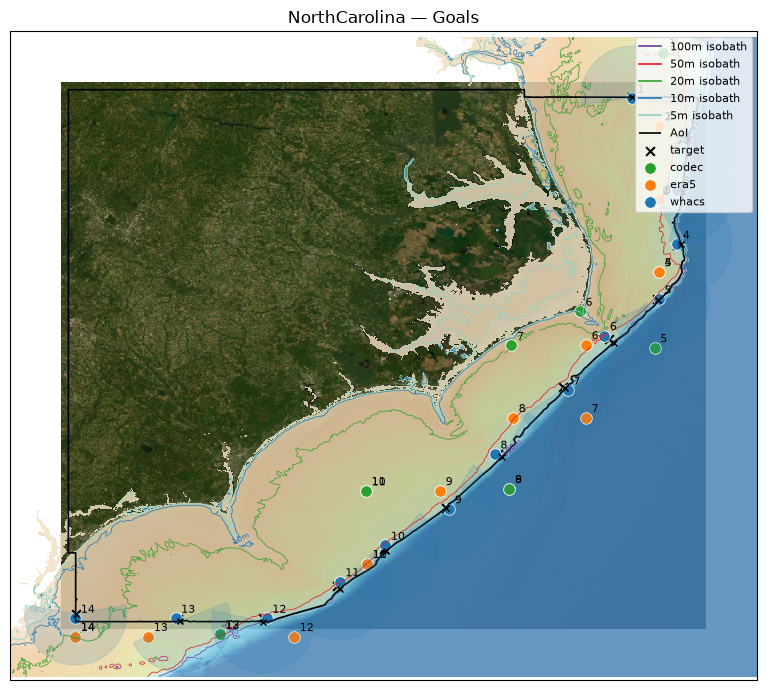

In [7]:
# Optionally edit this dictionary and rerun this cell.
# Goal 14 is the south-west corner of the mesh: waves enter there through the south side
# (from the east to the south-west) and the west side; the automatic sector missed the
# east-south-east, where WHACS has a large share of the energy at that node.
direction_overrides: dict[str, list[float]] = {
    "14": [80, 280],
}

goals_final = json.loads(json.dumps(goals))
for goal_id, angles in direction_overrides.items():
    if goal_id not in goals_final:
        raise KeyError(f"Unknown goal_id in direction_overrides: {goal_id}")
    if len(angles) != 2 or angles[0] >= angles[1]:
        raise ValueError(
            f"{goal_id}: angles must be [left, right] with left < right, got {angles}"
        )
    goals_final[goal_id]["angles"] = [float(angles[0]), float(angles[1])]

fig, ax = plot.plot_base_map(
    title="Goals",
    show_topobathy=True,
    show_satellite=True,
)
plot.plot_sectors(targets, goals_final, boundary_snaps, ax)
targets.plot(ax=ax, color="black", markersize=40, marker="x", label="target")

plot.plot_points(
    hc.hindcast_snaps_gdf(goals_final),
    ax,
    color_col="catalog",
    label_col="goal_id",
    color_map=plot.HINDCAST_COLORS,
)

minx, miny, maxx, maxy = aoi.total_bounds
pad = 0.4
ax.set_xlim(minx - pad, maxx + pad)
ax.set_ylim(miny - pad, maxy + pad)
ax.set_aspect("equal", adjustable="box")

fig.tight_layout()

## Save goals JSON and QGIS GeoPackage

After saving, update the case JSON with your selected goals JSON path:

```json
"simulations": {
    "goals_file": "inputs/goals/<Case>_Goals.json"
}
```

In [8]:
goals_to_save = goals_final if "goals_final" in locals() else goals

goals_out_path.parent.mkdir(parents=True, exist_ok=True)

with goals_out_path.open("w", encoding="utf-8") as f:
    json.dump({"goals": goals_to_save}, f, indent=4)
    f.write("\n")

hc.save_goals_gpkg(
    goals_to_save, targets, boundary_snaps, goals_gpkg_path, ring=ring_gdf
)

print(f"Wrote {len(goals_to_save)} goal(s) to:")
print(f"  {goals_out_path}")
print(f"  {goals_gpkg_path}")
print(
    "\nGPKG layers: targets, boundary_snaps, sectors, links, buffer_ring, "
    "codec, era5, whacs"
)
print(json.dumps({"goals": goals_to_save}, indent=4))

INFO:pyogrio._io:Created 14 records


INFO:pyogrio._io:Created 14 records


INFO:pyogrio._io:Created 14 records


INFO:pyogrio._io:Created 14 records


INFO:pyogrio._io:Created 1 records


INFO:pyogrio._io:Created 14 records


INFO:pyogrio._io:Created 14 records


INFO:pyogrio._io:Created 14 records


Wrote 14 goal(s) to:
  /lustre/geocean/WORK/users/javiert/projects/HyGloW/NorthCarolina/inputs/Goals/NorthCarolina_Goals.json
  /lustre/geocean/WORK/users/javiert/projects/HyGloW/NorthCarolina/inputs/Goals/NorthCarolina_Goals.gpkg

GPKG layers: targets, boundary_snaps, sectors, links, buffer_ring, codec, era5, whacs
{
    "goals": {
        "1": {
            "target": {
                "longitude": -75.185606,
                "latitude": 36.695521
            },
            "angles": [
                -99.4,
                100.3
            ],
            "hindcast": {
                "codec": {
                    "fid": 81,
                    "longitude": -74.971,
                    "latitude": 37.002,
                    "distance_m": 39011.7
                },
                "era5": {
                    "fid": 132,
                    "longitude": -75.0,
                    "latitude": 36.5,
                    "distance_m": 27312.6
                },
                "whacs":